# World Happiness Data Science Project

## Project Objective
To analyze the World Happiness dataset and understand the factors associated with happiness across different countries.

## Tools and Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Analysis Performed
1. Dataset exploration and inspection.
2. Missing value identification and handling.
3. Statistical analysis.
4. Top 10 happiest countries.
5. Bottom 10 happiest countries.
6. GDP vs Happiness analysis.
7. Social Support vs Happiness analysis.
8. Correlation heatmap.
9. Regional happiness comparison.

## Key Findings
- Social support has a strong positive correlation with happiness (0.81).
- GDP per capita has a positive correlation with happiness (0.77).
- Healthy life expectancy also has a strong positive correlation (0.76).
- Generosity has a relatively weak correlation (0.13).
- Happiness scores vary across countries and regions.

## Conclusion
The analysis suggests that economic conditions, social support, health and freedom are associated with happiness levels. Data visualization helps us understand these relationships and identify meaningful patterns.

In [25]:
# Step 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [26]:
# Step 2: Load Dataset

url = "https://raw.githubusercontent.com/Escavine/World-Happiness/main/World-happiness-report-2024.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

print(df.head())

Dataset loaded successfully!
  Country name            Regional indicator  Ladder score  upperwhisker  \
0      Finland                Western Europe         7.741         7.815   
1      Denmark                Western Europe         7.583         7.665   
2      Iceland                Western Europe         7.525         7.618   
3       Sweden                Western Europe         7.344         7.422   
4       Israel  Middle East and North Africa         7.341         7.405   

   lowerwhisker  Log GDP per capita  Social support  Healthy life expectancy  \
0         7.667               1.844           1.572                    0.695   
1         7.500               1.908           1.520                    0.699   
2         7.433               1.881           1.617                    0.718   
3         7.267               1.878           1.501                    0.724   
4         7.277               1.803           1.513                    0.740   

   Freedom to make life choices  

In [27]:
# Step 3: Explore Dataset

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(143, 12)

Column Names:
['Country name', 'Regional indicator', 'Ladder score', 'upperwhisker', 'lowerwhisker', 'Log GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption', 'Dystopia + residual']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Country name                  143 non-null    object 
 1   Regional indicator            143 non-null    object 
 2   Ladder score                  143 non-null    float64
 3   upperwhisker                  143 non-null    float64
 4   lowerwhisker                  143 non-null    float64
 5   Log GDP per capita            140 non-null    float64
 6   Social support                140 non-null    float64
 7   Healthy life expectancy       140 non-null   

In [28]:
# Fill missing numerical values with median

numeric_columns = df.select_dtypes(
    include=np.number
).columns

for column in numeric_columns:
    df[column] = df[column].fillna(
        df[column].median()
    )

print("Missing values handled successfully!")

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing values handled successfully!

Missing Values After Cleaning:
Country name                    0
Regional indicator              0
Ladder score                    0
upperwhisker                    0
lowerwhisker                    0
Log GDP per capita              0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
Dystopia + residual             0
dtype: int64


In [29]:
# Statistical Analysis

print("Statistical Summary:")
print(df.describe())

Statistical Summary:
       Ladder score  upperwhisker  lowerwhisker  Log GDP per capita  \
count    143.000000    143.000000    143.000000          143.000000   
mean       5.527580      5.641175      5.413972            1.379913   
std        1.170717      1.155008      1.187133            0.420652   
min        1.721000      1.775000      1.667000            0.000000   
25%        4.726000      4.845500      4.606000            1.079000   
50%        5.785000      5.895000      5.674000            1.431500   
75%        6.416000      6.507500      6.319000            1.733000   
max        7.741000      7.815000      7.667000            2.141000   

       Social support  Healthy life expectancy  Freedom to make life choices  \
count      143.000000               143.000000                    143.000000   
mean         1.136493                 0.521486                      0.621049   
std          0.330111                 0.163223                      0.160793   
min          0.0000

In [30]:
# Top 10 Happiest Countries

top_10 = df.sort_values(
    by='Ladder score',
    ascending=False
).head(10)

print(top_10[['Country name', 'Ladder score']])

  Country name  Ladder score
0      Finland         7.741
1      Denmark         7.583
2      Iceland         7.525
3       Sweden         7.344
4       Israel         7.341
5  Netherlands         7.319
6       Norway         7.302
7   Luxembourg         7.122
8  Switzerland         7.060
9    Australia         7.057


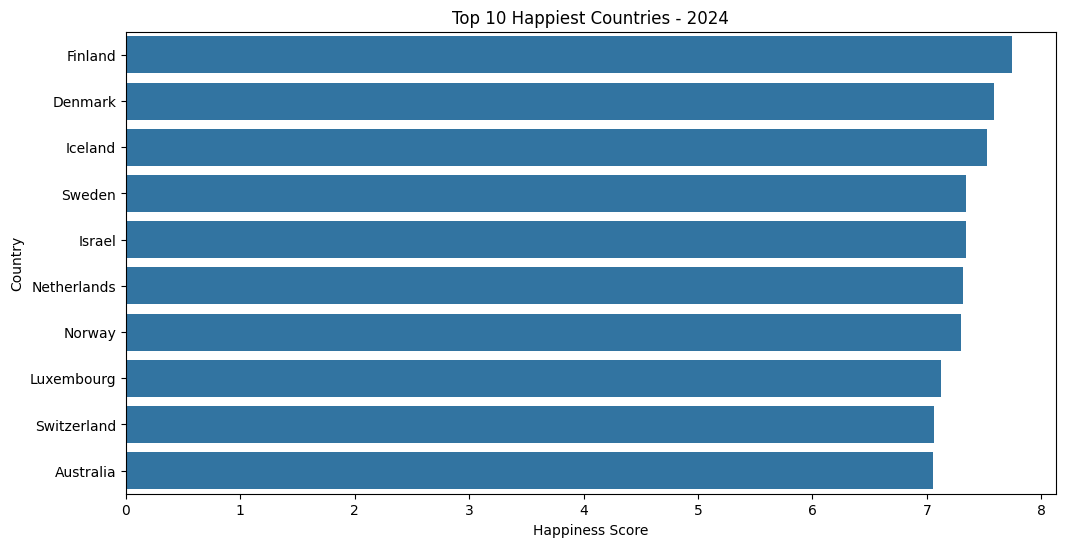

In [31]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_10,
    x='Ladder score',
    y='Country name'
)

plt.title("Top 10 Happiest Countries - 2024")
plt.xlabel("Happiness Score")
plt.ylabel("Country")

plt.show()

In [32]:
# Bottom 10 Least Happy Countries

bottom_10 = df.sort_values(
    by='Ladder score',
    ascending=True
).head(10)

print("10 Least Happy Countries:")
print(bottom_10[['Country name', 'Ladder score']])

10 Least Happy Countries:
         Country name  Ladder score
142       Afghanistan         1.721
141           Lebanon         2.707
140           Lesotho         3.186
139      Sierra Leone         3.245
138  Congo (Kinshasa)         3.295
137          Zimbabwe         3.341
136          Botswana         3.383
135            Malawi         3.421
134          Eswatini         3.502
133            Zambia         3.502


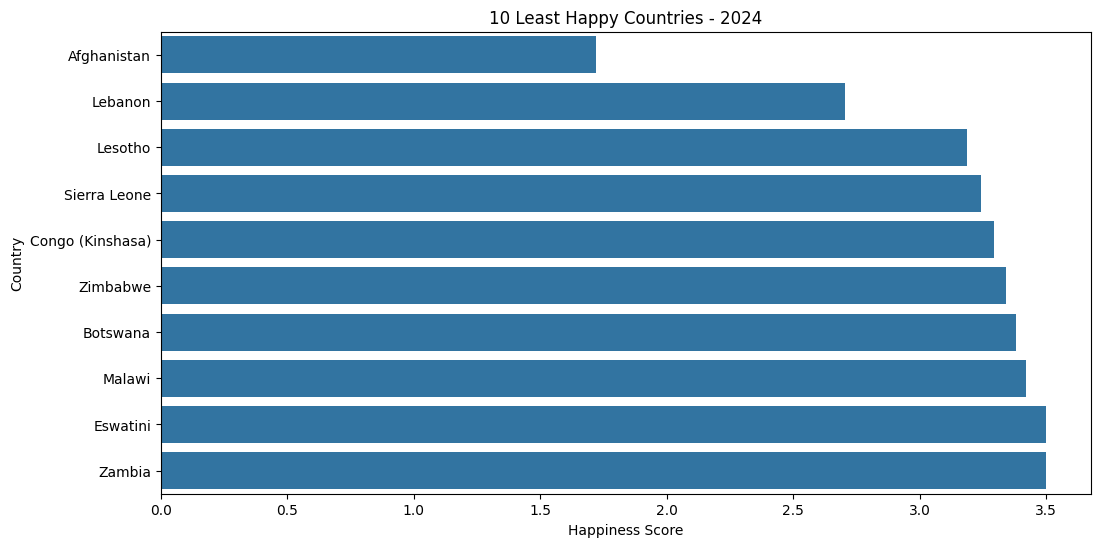

In [33]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=bottom_10,
    x='Ladder score',
    y='Country name'
)

plt.title("10 Least Happy Countries - 2024")
plt.xlabel("Happiness Score")
plt.ylabel("Country")

plt.show()

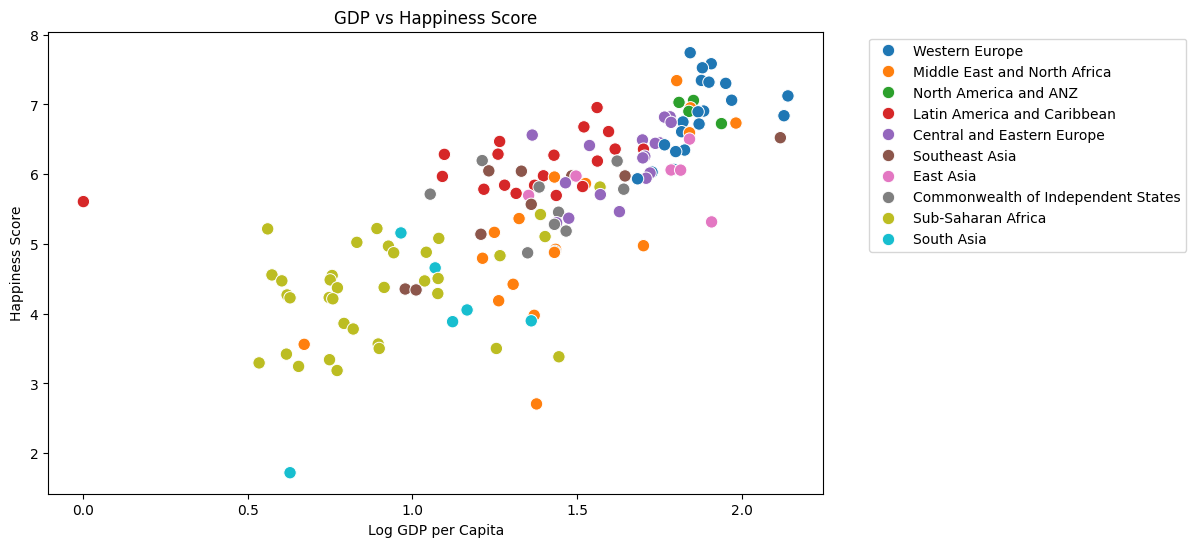

In [34]:
# GDP vs Happiness Scatter Plot

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='Log GDP per capita',
    y='Ladder score',
    hue='Regional indicator',
    s=80
)

plt.title("GDP vs Happiness Score")
plt.xlabel("Log GDP per Capita")
plt.ylabel("Happiness Score")

plt.legend(bbox_to_anchor=(1.05, 1))
plt.show()

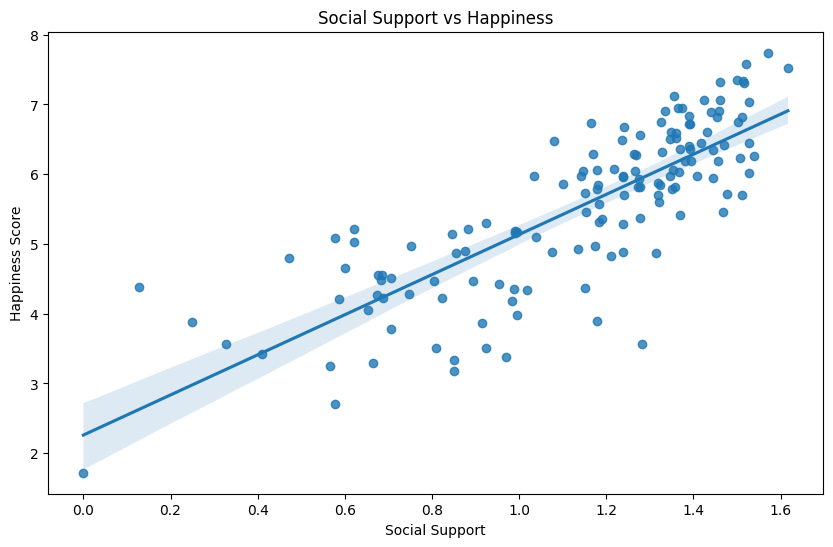

In [35]:
plt.figure(figsize=(10,6))

sns.regplot(
    data=df,
    x='Social support',
    y='Ladder score'
)

plt.title("Social Support vs Happiness")
plt.xlabel("Social Support")
plt.ylabel("Happiness Score")

plt.show()

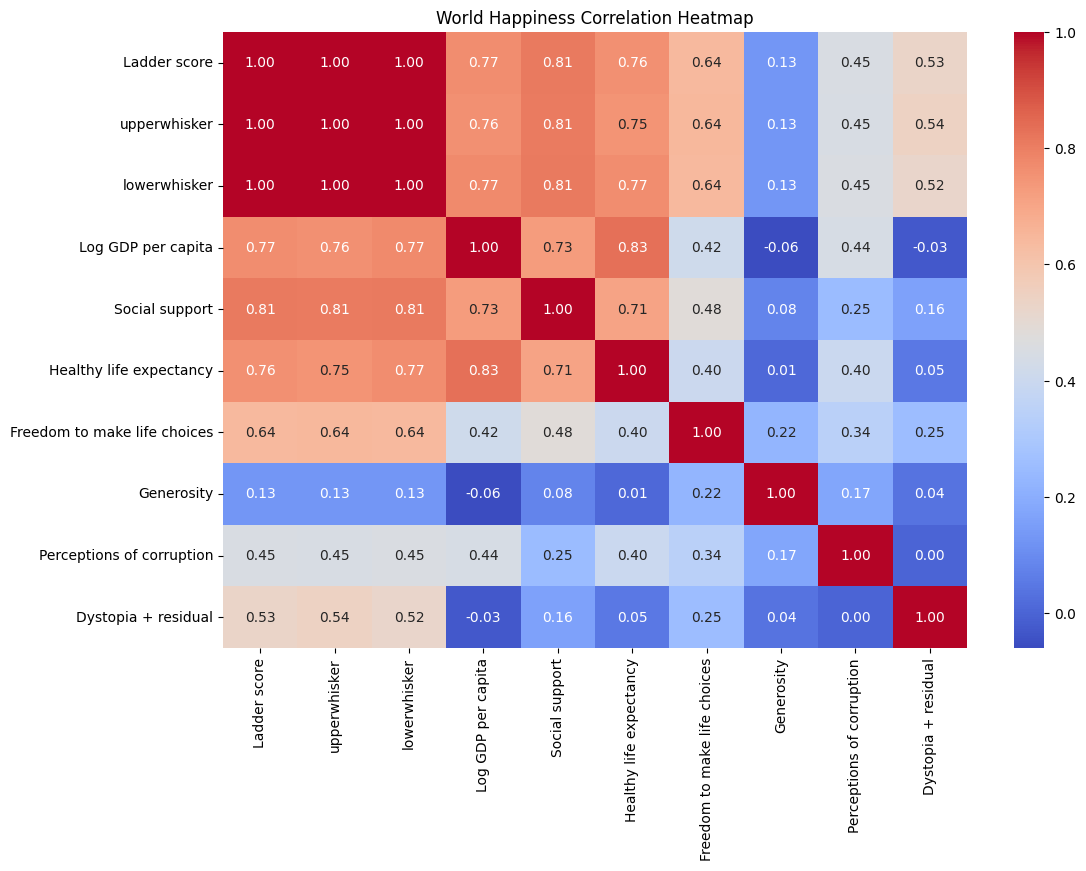

In [36]:
# Correlation Heatmap

plt.figure(figsize=(12,8))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("World Happiness Correlation Heatmap")

plt.show()

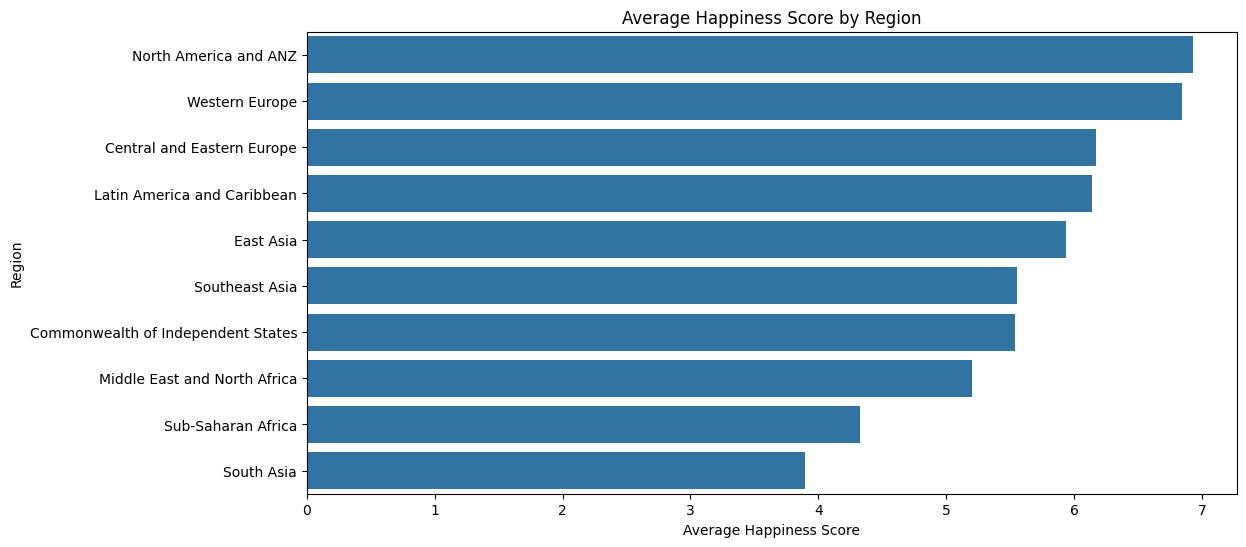

In [37]:
# Average Happiness by Region

region_happiness = df.groupby(
    'Regional indicator'
)['Ladder score'].mean().sort_values(
    ascending=False
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=region_happiness.values,
    y=region_happiness.index
)

plt.title("Average Happiness Score by Region")
plt.xlabel("Average Happiness Score")
plt.ylabel("Region")

plt.show()